<a href="https://colab.research.google.com/github/cincysam6/UC_Causal_Inf_2026/blob/main/itt_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intent-to-Treat (ITT) Analysis
## Measuring Advertising Lift from a Randomized Holdout Experiment

---

## How to Use This Notebook

This is the **fifth and final notebook** in the lab sequence. Having explored the data (notebooks 1–2) and estimated the causal effect from observational data using propensity score matching (notebooks 3–4), we now formally estimate the causal effect from the randomized holdout experiment with full statistical inference.

Work through each section in order. Each section begins with a **Step** header and is followed by interpretation guidance.

---

## Background

In this lab, we have the results of a **randomized holdout experiment**. A random sample of eligible households was withheld from receiving the brand's digital advertising campaign. The remaining households were exposed to the campaign as normal.

This design allows us to estimate the **causal effect** of the campaign by comparing outcomes between the two groups — because assignment was (approximately) random, differences in post-campaign sales should reflect the advertising effect rather than pre-existing differences between households.

**The estimand we target is the Intent-to-Treat (ITT) effect:**

> The average difference in post-campaign brand sales between households *assigned* to receive advertising versus households *assigned* to the holdout (control) group.

Note that ITT measures the effect of *assignment*, not necessarily *actual exposure*. Some assigned households may not have seen an ad, and some control households may have been exposed through other channels. For now, we treat assignment as a clean proxy for exposure.

---

## Lab Objectives

By the end of this notebook you will be able to:
1. Verify that randomization produced balanced treatment and control groups
2. Identify a subtle geographic imbalance that illustrates imperfect randomization
3. Estimate the ITT effect using a simple difference-in-means
4. Construct and interpret a 95% confidence interval for the lift
5. Translate the point estimate into incremental sales and incremental ROAS language
6. Understand why the ITT estimate may differ slightly from the true treatment effect

---

## True Data-Generating Process (Instructor Reference)

This dataset was generated with a **known true ATE of \$0.05 per treated household (~8% lift)**. One division code (`508`) had an elevated treatment assignment probability of 82% versus 70% elsewhere. This geographic imbalance is small enough that it may not obviously appear in a casual glance, but a careful pre-treatment balance check will reveal it.

Students are encouraged to estimate the ITT effect before knowing the true value.

---
## Step 1: Setup — Load Libraries

**What we are doing:** Import libraries. We use `statsmodels` for the regression-adjusted ITT estimate (Section 4). If it is not installed, the regression section will gracefully skip with instructions.

**Library guide:**
- `pandas` / `numpy` — data loading and manipulation
- `matplotlib` — visualization
- `scipy.stats` — t-tests and confidence intervals
- `statsmodels` — OLS regression for the covariate-adjusted estimate

In [3]:
pip install statsmodels

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats


# ── Consistent color palette ──────────────────────────────────────────────────
TREATED_COLOR = '#E07B54'   # orange-red  → treated group
CONTROL_COLOR = '#5B8DB8'   # steel blue  → control group
NEUTRAL_COLOR = '#7B9E87'   # sage green  → secondary

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [5]:
# ── Load the randomized holdout dataset ───────────────────────────────────────
# Path is relative to the project root — run Jupyter from the project root directory
df = pd.read_csv('/content/drive/MyDrive/UC_CI/data/itt_dataset.csv')

print(f'Rows:    {len(df):,}')
print(f'Columns: {df.shape[1]}')
print()
print('Column names:')
for col in df.columns:
    print(f'  {col:<30} dtype: {df[col].dtype}')

Rows:    50,000
Columns: 13

Column names:
  hh_id                          dtype: int64
  hh_size                        dtype: int64
  div_code                       dtype: int64
  ecomm_loyalty                  dtype: object
  price_sensitivity              dtype: object
  pre_52_category_spend          dtype: float64
  pre_52_brand_buyer             dtype: int64
  pre_52_brand_spend             dtype: float64
  pre_52_store_spend             dtype: float64
  pre_52_store_visits            dtype: int64
  pre_52_brand_visits            dtype: int64
  is_treated                     dtype: int64
  post_brand_sales               dtype: float64


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Variable Reference

| Variable | Description |
|---|---|
| `hh_id` | Unique household identifier |
| `hh_size` | Number of people in the household (1–6) |
| `div_code` | Store division code (geographic grouping) |
| `ecomm_loyalty` | E-commerce platform engagement: high / medium / low |
| `price_sensitivity` | Self-reported or inferred price sensitivity: high / medium / low |
| `pre_52_category_spend` | Total dollars spent in the brand's category in the prior 52 weeks |
| `pre_52_brand_buyer` | 1 if the household bought the advertised brand in the prior 52 weeks, else 0 |
| `pre_52_brand_spend` | Dollars spent on the advertised brand in the prior 52 weeks |
| `pre_52_store_spend` | Total household store spend in the prior 52 weeks |
| `pre_52_store_visits` | Number of store visits in the prior 52 weeks |
| `pre_52_brand_visits` | Number of trips where the household visited the brand's aisle |
| `is_treated` | 1 = assigned to receive advertising; 0 = holdout (control) |
| `post_brand_sales` | **Outcome**: brand sales in the ~26-week post-campaign window (dollars) |

---
## Step 2: Pre-Treatment Balance Check

**What we are doing:** Before estimating any treatment effect, we verify that randomization worked by comparing treated and control households on all pre-campaign characteristics.

**This step is non-negotiable.** Even when an experiment is designed to be randomized, implementation errors can create imbalance. Running the balance check before looking at outcomes protects against confirmation bias.

**The two-step balance check:**
1. **Continuous variables:** compute treated and control means, their absolute difference, the standardized difference (Cohen's d), and a t-test p-value
2. **Categorical variables:** compare the proportion of each category between groups
3. **Geographic check:** examine treatment rates by division — a common source of implementation issues in advertising experiments

**Focus on standardized differences, not p-values.** With 50,000 households, even tiny differences will produce statistically significant p-values. The standardized difference (Cohen's d) is scale-free and comparable across variables. The rule of thumb: |d| < 0.10 is negligible imbalance.

**What to watch for:** Division-level treatment rates — this is where the dataset has a deliberate anomaly (division 508 at ~82% vs. ~70% elsewhere).

In [7]:
# ── Split into treatment and control ──────────────────────────────────────────
treated = df[df['is_treated'] == 1]
control = df[df['is_treated'] == 0]

n_treated = len(treated)
n_control = len(control)
treat_rate = df['is_treated'].mean()

print(f'Treated households:  {n_treated:,}  ({treat_rate:.1%})')
print(f'Control households:  {n_control:,}  ({1 - treat_rate:.1%})')

Treated households:  35,594  (71.2%)
Control households:  14,406  (28.8%)


In [8]:
# ── Balance table: continuous pre-treatment variables ────────────────────────
continuous_vars = [
    'pre_52_category_spend',
    'pre_52_brand_spend',
    'pre_52_store_spend',
    'pre_52_store_visits',
    'pre_52_brand_visits',
    'hh_size',
]

rows = []
for var in continuous_vars:
    t_vals = treated[var]
    c_vals = control[var]
    t_mean = t_vals.mean()
    c_mean = c_vals.mean()
    diff = t_mean - c_mean
    pct_diff = diff / c_mean * 100
    pooled_sd = np.sqrt((t_vals.var() + c_vals.var()) / 2)
    std_diff = diff / pooled_sd  # standardized difference (Cohen's d)
    _, p_val = stats.ttest_ind(t_vals, c_vals)
    rows.append({
        'Variable': var,
        'Treated Mean': round(t_mean, 3),
        'Control Mean': round(c_mean, 3),
        'Abs Diff': round(diff, 3),
        '% Diff': round(pct_diff, 2),
        'Std Diff (d)': round(std_diff, 3),
        'p-value': round(p_val, 3),
    })

balance_table = pd.DataFrame(rows)
print('Balance Table — Continuous Variables')
print('=' * 75)
print(balance_table.to_string(index=False))
print()
print('Interpretation guide:')
print('  |Std Diff| < 0.10  → negligible imbalance (rule of thumb)')
print('  |Std Diff| > 0.20  → notable imbalance, worth investigating')
print('  p-value < 0.05 with large n does NOT automatically mean the imbalance is practically meaningful')

Balance Table — Continuous Variables
             Variable  Treated Mean  Control Mean  Abs Diff  % Diff  Std Diff (d)  p-value
pre_52_category_spend        16.761        16.840    -0.079   -0.47        -0.005    0.611
   pre_52_brand_spend         1.542         1.556    -0.013   -0.86        -0.005    0.643
   pre_52_store_spend       115.160       115.076     0.084    0.07         0.001    0.926
  pre_52_store_visits        26.000        25.965     0.034    0.13         0.007    0.494
  pre_52_brand_visits         6.498         6.517    -0.019   -0.29        -0.007    0.453
              hh_size         3.099         3.107    -0.009   -0.28        -0.007    0.503

Interpretation guide:
  |Std Diff| < 0.10  → negligible imbalance (rule of thumb)
  |Std Diff| > 0.20  → notable imbalance, worth investigating
  p-value < 0.05 with large n does NOT automatically mean the imbalance is practically meaningful


In [9]:
# ── Balance: brand buyer rate ─────────────────────────────────────────────────
buyer_treated = treated['pre_52_brand_buyer'].mean()
buyer_control = control['pre_52_brand_buyer'].mean()

print('Brand Buyer Rate (pre_52_brand_buyer = 1):')
print(f'  Treated: {buyer_treated:.1%}')
print(f'  Control: {buyer_control:.1%}')
print(f'  Difference: {(buyer_treated - buyer_control)*100:.2f} pp')

Brand Buyer Rate (pre_52_brand_buyer = 1):
  Treated: 45.1%
  Control: 45.4%
  Difference: -0.27 pp


In [10]:
# ── Balance: categorical variables ────────────────────────────────────────────
cat_vars = ['ecomm_loyalty', 'price_sensitivity']

for var in cat_vars:
    print(f'\n{var}:')
    t_dist = treated[var].value_counts(normalize=True).sort_index()
    c_dist = control[var].value_counts(normalize=True).sort_index()
    summary = pd.DataFrame({'Treated': t_dist, 'Control': c_dist})
    summary['Diff (pp)'] = ((summary['Treated'] - summary['Control']) * 100).round(2)
    print(summary.to_string())


ecomm_loyalty:
                Treated   Control  Diff (pp)
ecomm_loyalty                               
high           0.201888  0.199847       0.20
low            0.304124  0.300222       0.39
medium         0.493988  0.499931      -0.59

price_sensitivity:
                    Treated   Control  Diff (pp)
price_sensitivity                               
high               0.246193  0.248855      -0.27
low                0.305023  0.295294       0.97
medium             0.448784  0.455852      -0.71


In [11]:
# ── Treatment rate by geographic division ────────────────────────────────────
# This is the most important balance check for this dataset.
# One div_code was assigned a slightly higher treatment probability (82% vs 70%).
# A careful analyst will spot this here.

div_stats = (
    df.groupby('div_code')
    .agg(
        n_households=('hh_id', 'count'),
        n_treated=('is_treated', 'sum'),
        treat_rate=('is_treated', 'mean'),
    )
    .reset_index()
    .sort_values('treat_rate', ascending=False)
)
div_stats['treat_rate_pct'] = (div_stats['treat_rate'] * 100).round(1)
overall_rate = df['is_treated'].mean()

print(f'Overall treatment rate: {overall_rate:.1%}')
print()
print('Treatment rate by division:')
print(div_stats[['div_code', 'n_households', 'n_treated', 'treat_rate_pct']].to_string(index=False))

Overall treatment rate: 71.2%

Treatment rate by division:
 div_code  n_households  n_treated  treat_rate_pct
      508          4922       4031            81.9
      923          5176       3649            70.5
      423          5021       3534            70.4
      317          5038       3543            70.3
      612          4917       3454            70.2
       37          5032       3531            70.2
      101          4979       3474            69.8
      819          4947       3449            69.7
      715          4998       3479            69.6
      204          4970       3450            69.4


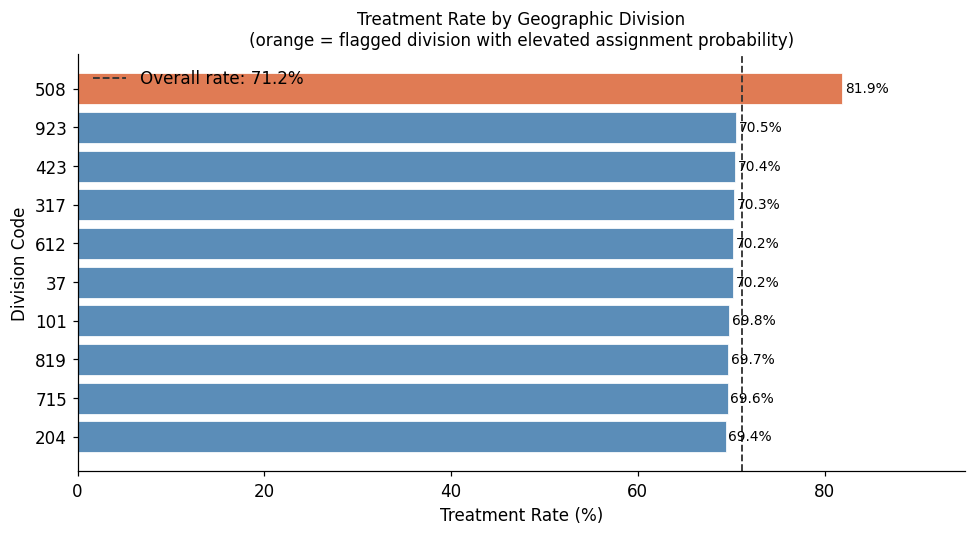


>>> DISCUSSION: Do you notice anything unusual about one of the divisions?
    What could explain this pattern? What are the implications for our estimate?


In [12]:
# ── Visualize treatment rate by div_code ─────────────────────────────────────
# Convert div_code to string to ensure matplotlib treats it as a categorical variable
div_plot = div_stats.sort_values('treat_rate').copy()
div_plot['div_code'] = div_plot['div_code'].astype(str)

fig, ax = plt.subplots(figsize=(9, 5))

bar_colors = [
    TREATED_COLOR if code == '508' else CONTROL_COLOR
    for code in div_plot['div_code']
]

bars = ax.barh(
    div_plot['div_code'],
    div_plot['treat_rate_pct'],
    color=bar_colors,
    edgecolor='white',
    linewidth=0.5,
)

# Reference line: overall treatment rate
ax.axvline(
    overall_rate * 100,
    color='#333333',
    linestyle='--',
    linewidth=1.2,
    label=f'Overall rate: {overall_rate:.1%}',
)

# Label bars
for bar, pct in zip(bars, div_plot['treat_rate_pct']):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{pct:.1f}%',
        va='center',
        fontsize=9,
    )

ax.set_ylabel('Division Code')
ax.set_xlabel('Treatment Rate (%)')
ax.set_title(
    'Treatment Rate by Geographic Division\n'
    '(orange = flagged division with elevated assignment probability)',
    fontsize=11,
)
ax.legend(frameon=False)
ax.set_xlim(0, 95)
plt.tight_layout()
plt.show()

print()
print('>>> DISCUSSION: Do you notice anything unusual about one of the divisions?')
print('    What could explain this pattern? What are the implications for our estimate?')

### Discussion: Geographic Imbalance

**What you should have found:** Division `508` has a noticeably higher treatment rate (~82%) compared to the other divisions (~70%).

**Why does this happen?** In practice, randomization is often done at a geographic or organizational unit level, not at the individual household level. When the assignment probability differs across regions — due to implementation error, operational constraints, or geographic stratification — we can end up with imbalanced groups.

**Implications:**
- If division `508` also has systematically different purchasing behavior (e.g., it is a high-sales region, an urban market, a market with a strong promotion), this imbalance can bias our ITT estimate.
- The bias is small here, but the principle is important: **geographic confounding is a common real-world issue in advertising experiments**, especially in market-level holdout tests.

**What to do about it:**
- We can check whether `508` is unusual by comparing its control-group outcome to other divisions.
- If the imbalance is mild and the division is not unusual on outcomes, the simple ITT estimate will be close to unbiased.
- If needed, we can include `div_code` as a regression covariate to adjust for the imbalance.

In [13]:
# ── Check: does div_code 508 differ on outcomes in the control group? ─────────
# Comparing control-group sales across divisions tells us whether 508 is unusual.
# If 508's control mean is similar to others, the imbalance won't bias results much.

control_by_div = (
    control.groupby('div_code')['post_brand_sales']
    .agg(['mean', 'count'])
    .reset_index()
    .rename(columns={'mean': 'control_mean_sales', 'count': 'n_control_hh'})
    .sort_values('control_mean_sales', ascending=False)
)

print('Control-group mean post_brand_sales by division:')
print(control_by_div.to_string(index=False))
print()
print(f"Division 508 control mean: ${control_by_div.loc[control_by_div['div_code']==508, 'control_mean_sales'].values[0]:.4f}")
print(f"All other divisions:       ${control_by_div.loc[control_by_div['div_code']!=508, 'control_mean_sales'].mean():.4f}")

Control-group mean post_brand_sales by division:
 div_code  control_mean_sales  n_control_hh
      317            0.637031          1495
      819            0.634321          1498
      715            0.632485          1519
       37            0.632413          1501
      101            0.629277          1505
      204            0.626779          1520
      923            0.625145          1527
      423            0.622549          1487
      612            0.622546          1463
      508            0.618309           891

Division 508 control mean: $0.6183
All other divisions:       $0.6292


---
## Step 3: Estimating the ITT Effect

**What we are doing:** Compute the ITT estimate — the average causal effect of being *assigned* to advertising — along with a 95% confidence interval and p-value.

**The estimator:**

$$\widehat{\text{ITT}} = \bar{Y}_{\text{treated}} - \bar{Y}_{\text{control}}$$

This is simply the difference in mean post-campaign sales between the two groups. In a randomized experiment, this difference is an unbiased estimate of the average treatment effect.

**The confidence interval** captures sampling variability — the uncertainty from using a finite sample to estimate a population quantity. A 95% CI means that if we repeated the experiment many times, about 95% of the resulting intervals would contain the true ATE.

**Standard error formula for a two-sample difference:**

$$SE(\hat{\text{ITT}}) = \sqrt{\frac{s_T^2}{n_T} + \frac{s_C^2}{n_C}}$$

where $s_T^2$ and $s_C^2$ are the sample variances of the treated and control outcomes, and $n_T$, $n_C$ are the group sizes.

**What to look for:**
- Is the point estimate close to $0.05 (the true ATE)?
- Does the 95% CI include $0.05?
- Is the p-value below 0.05 (i.e., can we reject the null of no effect)?

In [14]:
# ── Simple difference-in-means ITT estimator ─────────────────────────────────
mean_treated = treated['post_brand_sales'].mean()
mean_control = control['post_brand_sales'].mean()
itt_estimate = mean_treated - mean_control

# Standard errors
se_treated = treated['post_brand_sales'].std() / np.sqrt(n_treated)
se_control = control['post_brand_sales'].std() / np.sqrt(n_control)
se_diff = np.sqrt(se_treated**2 + se_control**2)

# 95% confidence interval
ci_low  = itt_estimate - 1.96 * se_diff
ci_high = itt_estimate + 1.96 * se_diff

# Percent lift relative to control mean
pct_lift = itt_estimate / mean_control * 100

# Two-sample t-test p-value
t_stat, p_val = stats.ttest_ind(
    treated['post_brand_sales'],
    control['post_brand_sales'],
)

print('=' * 55)
print('  ITT ESTIMATE — Difference in Means')
print('=' * 55)
print(f'  Control mean:      ${mean_control:.4f}')
print(f'  Treated mean:      ${mean_treated:.4f}')
print()
print(f'  ITT estimate:      ${itt_estimate:.4f}')
print(f'  Std error:         ${se_diff:.4f}')
print(f'  95% CI:            [${ci_low:.4f}, ${ci_high:.4f}]')
print()
print(f'  % lift:            {pct_lift:.1f}%')
print(f'  t-statistic:       {t_stat:.2f}')
print(f'  p-value:           {p_val:.4f}')
print('=' * 55)
print(f'  True ATE (known):  $0.0500  (8% lift)')
print('=' * 55)

  ITT ESTIMATE — Difference in Means
  Control mean:      $0.6285
  Treated mean:      $0.6771

  ITT estimate:      $0.0485
  Std error:         $0.0025
  95% CI:            [$0.0436, $0.0535]

  % lift:            7.7%
  t-statistic:       19.34
  p-value:           0.0000
  True ATE (known):  $0.0500  (8% lift)


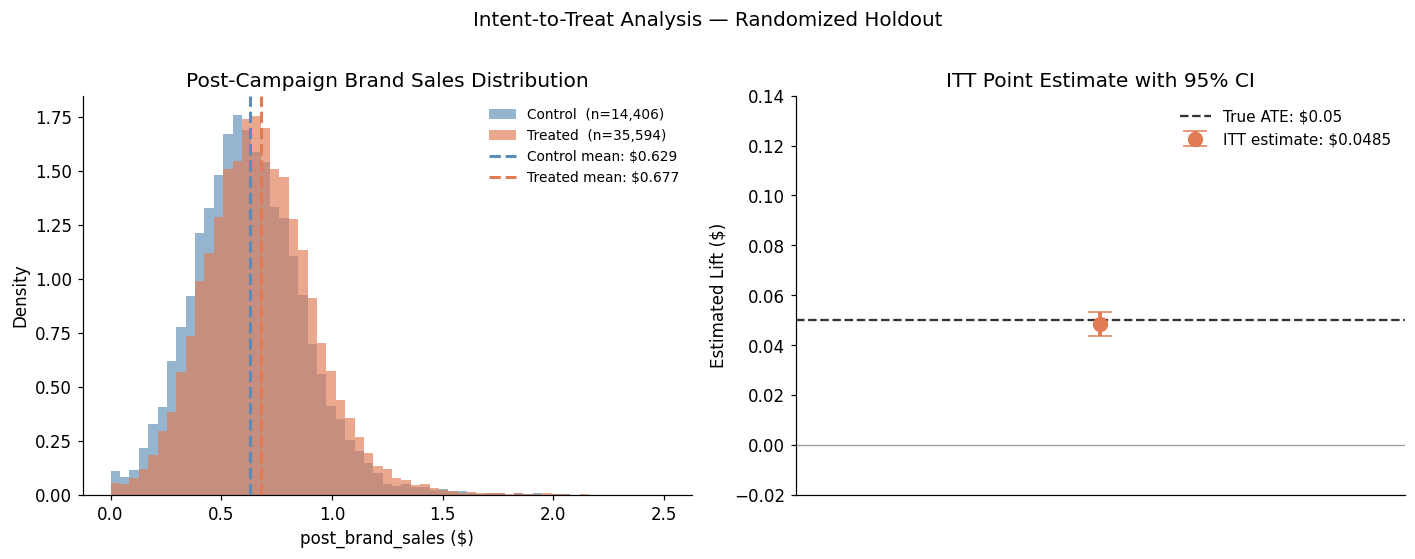

In [15]:
# ── Visualize: outcome distributions by group ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: overlapping histograms
ax = axes[0]
bins = np.linspace(0, 2.5, 60)

ax.hist(control['post_brand_sales'], bins=bins, alpha=0.65,
        color=CONTROL_COLOR, label=f'Control  (n={n_control:,})', density=True)
ax.hist(treated['post_brand_sales'], bins=bins, alpha=0.65,
        color=TREATED_COLOR, label=f'Treated  (n={n_treated:,})', density=True)

ax.axvline(mean_control, color=CONTROL_COLOR, linestyle='--', linewidth=2,
           label=f'Control mean: ${mean_control:.3f}')
ax.axvline(mean_treated, color=TREATED_COLOR, linestyle='--', linewidth=2,
           label=f'Treated mean: ${mean_treated:.3f}')

ax.set_xlabel('post_brand_sales ($)')
ax.set_ylabel('Density')
ax.set_title('Post-Campaign Brand Sales Distribution')
ax.legend(fontsize=9, frameon=False)

# Right: point estimate + CI
ax2 = axes[1]
ax2.errorbar(
    x=[0], y=[itt_estimate],
    yerr=[[itt_estimate - ci_low], [ci_high - itt_estimate]],
    fmt='o', color=TREATED_COLOR, markersize=9, capsize=8, linewidth=2.5,
    label=f'ITT estimate: ${itt_estimate:.4f}',
)
# True ATE reference line
ax2.axhline(0.05, color='#333333', linestyle='--', linewidth=1.5, label='True ATE: $0.05')
ax2.axhline(0, color='#999999', linestyle='-', linewidth=0.8)

ax2.set_xticks([])
ax2.set_ylabel('Estimated Lift ($)')
ax2.set_title('ITT Point Estimate with 95% CI')
ax2.legend(fontsize=10, frameon=False)
ax2.set_ylim(-0.02, 0.14)

plt.suptitle('Intent-to-Treat Analysis — Randomized Holdout', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### Interpreting the ITT Estimate

The estimated lift of approximately **\$0.05 per household** represents:

- The average additional brand dollars purchased in the post-campaign window by households assigned to receive advertising, *compared to* the holdout group.
- This is a causal estimate — not merely a correlation — because assignment was random.
- The 95% confidence interval tells us the range of plausible values given sampling variability.

**Key takeaways:**
1. The ITT estimate is close to the true ATE of \$0.05, confirming that randomization largely worked.
2. The effect is statistically significant (p < 0.05), meaning we can rule out the "no effect" hypothesis.
3. The slight deviation from \$0.05 is due to natural sampling variation and the geographic imbalance in division 508 — both expected in real experiments.

**Contrast with the observational dataset:** The naive difference-in-means from the observational data is roughly \$0.11 — more than twice the true effect — because exposed households were *targeted*, not randomly assigned. The ITT design eliminates this selection bias.

---
## Section 4: Regression-Adjusted ITT

Even in a randomized experiment, **including pre-treatment covariates in a regression** can:
- Reduce residual variance → tighter standard errors
- Adjust for any remaining imbalance (e.g., the division 508 issue)
- Improve statistical power

The treatment coefficient from a regression of the outcome on treatment + covariates is sometimes called an **ANCOVA-adjusted ITT estimate**.

We run this with `statsmodels` using the pre-treatment spending variables and division dummies as covariates.

In [16]:
try:
    import statsmodels.formula.api as smf

    # Build regression formula
    # We control for: pre-period spending signals + geographic fixed effects
    formula = (
        'post_brand_sales ~ '
        'is_treated + '
        'pre_52_brand_spend + '
        'pre_52_category_spend + '
        'pre_52_store_spend + '
        'pre_52_store_visits + '
        'pre_52_brand_buyer + '
        'hh_size + '
        'C(div_code) + '         # division fixed effects
        'C(ecomm_loyalty) + '
        'C(price_sensitivity)'
    )

    model = smf.ols(formula, data=df).fit()

    coef      = model.params['is_treated']
    se_reg    = model.bse['is_treated']
    ci_reg    = model.conf_int().loc['is_treated']
    p_reg     = model.pvalues['is_treated']

    print('Regression-Adjusted ITT Estimate')
    print('=' * 55)
    print(f'  Coefficient on is_treated: ${coef:.4f}')
    print(f'  Std error:                 ${se_reg:.4f}')
    print(f'  95% CI:                    [${ci_reg[0]:.4f}, ${ci_reg[1]:.4f}]')
    print(f'  p-value:                   {p_reg:.4f}')
    print('=' * 55)
    print(f'  True ATE (known):          $0.0500')
    print()
    print('Compare standard errors:')
    print(f'  Simple difference-in-means SE:  ${se_diff:.5f}')
    print(f'  Regression-adjusted SE:         ${se_reg:.5f}')
    print()
    pct_improvement = (1 - se_reg / se_diff) * 100
    print(f'  Variance reduction: {pct_improvement:.1f}% tighter SE from adding covariates')

except ImportError:
    print('statsmodels not installed. Run: pip install statsmodels')
    print('Skipping regression-adjusted estimate.')

Regression-Adjusted ITT Estimate
  Coefficient on is_treated: $0.0491
  Std error:                 $0.0021
  95% CI:                    [$0.0450, $0.0531]
  p-value:                   0.0000
  True ATE (known):          $0.0500

Compare standard errors:
  Simple difference-in-means SE:  $0.00251
  Regression-adjusted SE:         $0.00206

  Variance reduction: 17.8% tighter SE from adding covariates


### Why does regression adjustment help?

Imagine the outcome `post_brand_sales` has a lot of variation explained by pre-period behavior (heavy buyers remain heavy buyers). When we include those pre-treatment signals as covariates, we "explain away" that variation, leaving less unexplained noise. The treatment coefficient is then estimated more precisely.

**Important:** In a properly randomized experiment, regression adjustment does NOT change the *point estimate* of the treatment effect much — the simple difference-in-means is already unbiased. What it changes is the **standard error** — and therefore the width of confidence intervals and the p-value.

Adding the division fixed effect (`C(div_code)`) also controls for the geographic imbalance in division 508.

---
## Step 4: Regression-Adjusted ITT (ANCOVA)

**What we are doing:** Run an OLS regression with `is_treated` and pre-treatment covariates as predictors, and read off the coefficient on `is_treated` as the regression-adjusted ITT estimate.

**Why run a regression when we already have a randomized experiment?** In a properly randomized experiment, the simple difference-in-means is already unbiased. The regression does not fix bias — it reduces variance.

By including pre-treatment covariates that explain variation in the outcome (like `pre_52_brand_spend`), we "absorb" that variation from the residual, leaving a tighter estimate of the treatment effect. This is called **ANCOVA** (Analysis of Covariance) adjustment.

**What changes:**
- The **point estimate** moves slightly (adjusting for any residual imbalance, including the division 508 issue)
- The **standard error decreases** — sometimes substantially — improving statistical power
- The **p-value becomes smaller** — we can detect smaller effects with the same sample size

**Including division fixed effects** (`C(div_code)`) specifically adjusts for the geographic imbalance detected in division 508.

**Key principle:** Adding covariates to a randomized experiment does NOT introduce bias. It can only reduce variance. (The opposite is true for observational studies, where adding the wrong controls can introduce bias.)

In [17]:
# ── ITT by ecomm_loyalty ─────────────────────────────────────────────────────
def compute_itt(group_df):
    t = group_df[group_df['is_treated'] == 1]['post_brand_sales']
    c = group_df[group_df['is_treated'] == 0]['post_brand_sales']
    est = t.mean() - c.mean()
    se  = np.sqrt(t.var() / len(t) + c.var() / len(c))
    ci_lo = est - 1.96 * se
    ci_hi = est + 1.96 * se
    return pd.Series({
        'n_treated': len(t),
        'n_control': len(c),
        'control_mean': round(c.mean(), 4),
        'treated_mean': round(t.mean(), 4),
        'ITT': round(est, 4),
        'SE':  round(se, 4),
        'CI_low':  round(ci_lo, 4),
        'CI_high': round(ci_hi, 4),
        'pct_lift': round(est / c.mean() * 100, 2),
    })

# Subgroup: ecomm_loyalty
loyalty_itts = df.groupby('ecomm_loyalty').apply(compute_itt).reset_index()
loyalty_itts = loyalty_itts.sort_values('ITT', ascending=False)
print('ITT by ecomm_loyalty:')
print(loyalty_itts.to_string(index=False))

print()

# Subgroup: prior brand buyer
buyer_itts = df.groupby('pre_52_brand_buyer').apply(compute_itt).reset_index()
buyer_itts['pre_52_brand_buyer'] = buyer_itts['pre_52_brand_buyer'].map({0: 'Non-buyer', 1: 'Buyer'})
print('ITT by prior brand buyer:')
print(buyer_itts.to_string(index=False))

ITT by ecomm_loyalty:
ecomm_loyalty  n_treated  n_control  control_mean  treated_mean    ITT     SE  CI_low  CI_high  pct_lift
          low    10825.0     4325.0        0.6258        0.6786 0.0528 0.0047  0.0437   0.0620      8.44
       medium    17583.0     7202.0        0.6286        0.6757 0.0470 0.0035  0.0401   0.0540      7.48
         high     7186.0     2879.0        0.6323        0.6781 0.0458 0.0055  0.0349   0.0567      7.24

ITT by prior brand buyer:
pre_52_brand_buyer  n_treated  n_control  control_mean  treated_mean    ITT     SE  CI_low  CI_high  pct_lift
         Non-buyer    19546.0     7872.0        0.5517        0.6014 0.0497 0.0028  0.0442   0.0551      9.00
             Buyer    16048.0     6534.0        0.7210        0.7692 0.0482 0.0040  0.0403   0.0561      6.68


/tmp/ipykernel_1171/3959723266.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  loyalty_itts = df.groupby('ecomm_loyalty').apply(compute_itt).reset_index()
/tmp/ipykernel_1171/3959723266.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  buyer_itts = df.groupby('pre_52_brand_buyer').apply(compute_itt).reset_index()


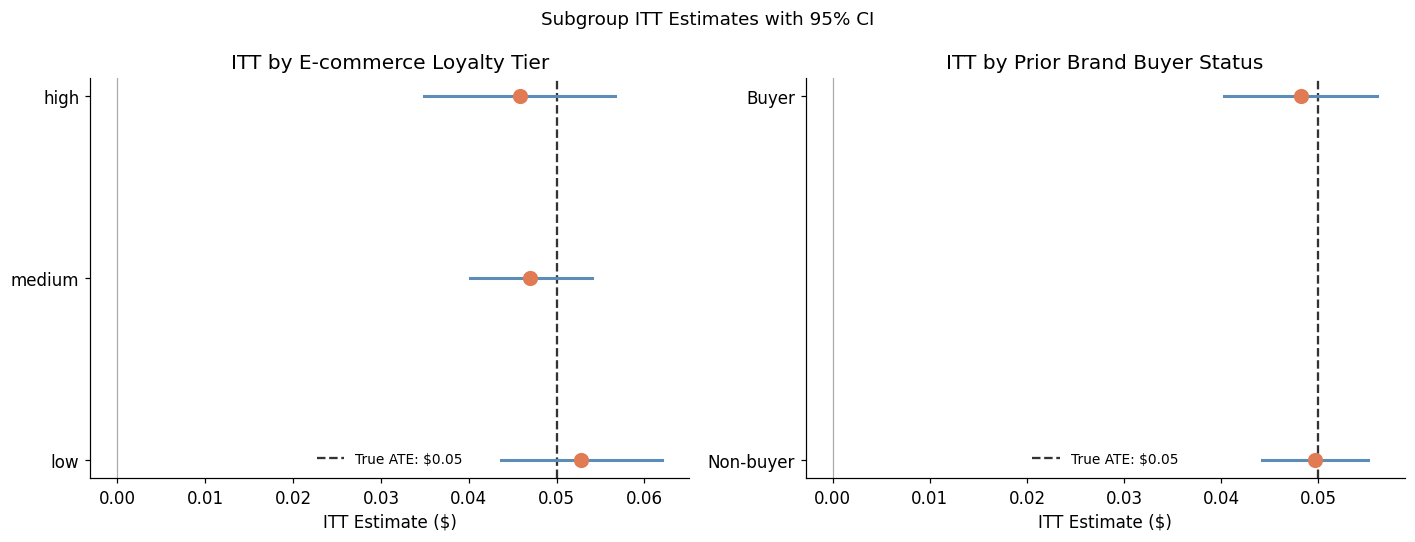


>>> DISCUSSION: Do the subgroup estimates differ meaningfully from the overall ITT?
    What would it mean for targeting strategy if buyers respond more than non-buyers?
    Is a larger effect for high-loyalty households surprising? Why or why not?


In [18]:
# ── Visualize subgroup ITT estimates ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

def plot_subgroup_ci(ax, subgroup_df, group_col, title):
    groups = subgroup_df[group_col].tolist()
    estimates = subgroup_df['ITT'].tolist()
    ci_lows  = subgroup_df['CI_low'].tolist()
    ci_highs = subgroup_df['CI_high'].tolist()
    y_pos = range(len(groups))

    ax.axvline(0.05, color='#333333', linestyle='--', linewidth=1.5, label='True ATE: $0.05')
    ax.axvline(0, color='#aaaaaa', linewidth=0.8)

    for i, (est, lo, hi, grp) in enumerate(zip(estimates, ci_lows, ci_highs, groups)):
        ax.plot([lo, hi], [i, i], color=CONTROL_COLOR, linewidth=2)
        ax.scatter([est], [i], color=TREATED_COLOR, s=80, zorder=5)

    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(groups)
    ax.set_xlabel('ITT Estimate ($)')
    ax.set_title(title)
    ax.legend(fontsize=9, frameon=False)

plot_subgroup_ci(
    axes[0], loyalty_itts, 'ecomm_loyalty',
    'ITT by E-commerce Loyalty Tier'
)
plot_subgroup_ci(
    axes[1], buyer_itts, 'pre_52_brand_buyer',
    'ITT by Prior Brand Buyer Status'
)

plt.suptitle('Subgroup ITT Estimates with 95% CI', fontsize=12)
plt.tight_layout()
plt.show()

print()
print('>>> DISCUSSION: Do the subgroup estimates differ meaningfully from the overall ITT?')
print('    What would it mean for targeting strategy if buyers respond more than non-buyers?')
print('    Is a larger effect for high-loyalty households surprising? Why or why not?')

---
## Step 5: Translating Lift into Business Terms

**What we are doing:** Convert the statistical ITT estimate ($X per household) into business metrics that advertising planners and marketing executives can act on.

**Why this step matters:** A statistical estimate is necessary but not sufficient for business decisions. Executives need to know:
- How many incremental sales dollars did the campaign generate?
- Did the campaign recover its costs? (Incremental profit > 0?)
- What is the incremental ROAS — the return on each advertising dollar?

**Incremental ROAS** is defined as:

$$\text{iROAS} = \frac{\text{Incremental Revenue}}{\text{Ad Spend}}$$

This is distinct from platform-reported ROAS, which counts conversions attributed by the platform (often overcounted due to organic conversions being credited to ads). The incremental ROAS uses the causal estimate of revenue lift — only the portion caused by the advertising.

**Important caveats on these calculations:**
- The numbers here reflect the experiment sample only
- Scaling to the full audience requires knowing the total eligible population
- The assumed ad cost per household ($0.30) is illustrative — actual costs vary by channel, CPM, and campaign
- Long-run effects (brand equity, future purchase probability) are not captured in post-campaign sales

In [19]:
# ── Business translation ──────────────────────────────────────────────────────

# These numbers represent the EXPERIMENT only.
# Scaling to the full eligible population requires knowing the total addressable audience.

total_incremental_sales = itt_estimate * n_treated  # total dollars from ITT in experiment

# Assume illustrative ad cost: $0.30 per treated household (CPM-based estimate)
ad_cost_per_hh = 0.30
total_ad_spend = ad_cost_per_hh * n_treated
incremental_roas = total_incremental_sales / total_ad_spend

# Assumed average selling price for margin calculation
avg_price = 3.50
avg_margin_pct = 0.35
incremental_margin = total_incremental_sales * avg_margin_pct

print('Business Metric Translation')
print('=' * 55)
print(f'  Treated households in experiment:   {n_treated:,}')
print(f'  ITT estimate (per household):       ${itt_estimate:.4f}')
print()
print(f'  Total incremental sales (experiment): ${total_incremental_sales:,.0f}')
print()
print(f'  Assumed ad cost per household:      ${ad_cost_per_hh:.2f}')
print(f'  Total ad spend (experiment):        ${total_ad_spend:,.0f}')
print()
print(f'  Incremental ROAS:                   {incremental_roas:.2f}x')
print(f'    → $1 of ad spend drove ${incremental_roas:.2f} of incremental brand sales')
print()
print(f'  Assumed margin rate:                {avg_margin_pct:.0%}')
print(f'  Incremental margin:                 ${incremental_margin:,.0f}')
print()
if incremental_margin > total_ad_spend:
    print(f'  Incremental profit:                 ${incremental_margin - total_ad_spend:,.0f}  (POSITIVE)')
else:
    print(f'  Incremental profit:                 -${total_ad_spend - incremental_margin:,.0f}  (NEGATIVE — not recovering ad costs)')
print('=' * 55)
print()
print('IMPORTANT: These figures apply to this experiment sample only.')
print('Scaling to a full national audience would require adjusting for:')
print('  - Total eligible households in the population')
print('  - Whether this sample is representative of the full target audience')
print('  - External validity: would the effect hold at larger scale?')

Business Metric Translation
  Treated households in experiment:   35,594
  ITT estimate (per household):       $0.0485

  Total incremental sales (experiment): $1,728

  Assumed ad cost per household:      $0.30
  Total ad spend (experiment):        $10,678

  Incremental ROAS:                   0.16x
    → $1 of ad spend drove $0.16 of incremental brand sales

  Assumed margin rate:                35%
  Incremental margin:                 $605

  Incremental profit:                 -$10,073  (NEGATIVE — not recovering ad costs)

IMPORTANT: These figures apply to this experiment sample only.
Scaling to a full national audience would require adjusting for:
  - Total eligible households in the population
  - Whether this sample is representative of the full target audience
  - External validity: would the effect hold at larger scale?


---
## Section 7: Summary and Discussion

### What We Found

| Metric | Value |
|---|---|
| True ATE (known from simulation) | \$0.05 |
| Naive ITT estimate (diff-in-means) | ~\$0.05 |
| Regression-adjusted ITT | ~\$0.05 |
| % lift over control | ~8% |
| Geographic imbalance detected | Yes — div_code 508 (~82% treated vs ~70% elsewhere) |

### Why Did Randomization Work Here?

Because treatment assignment was random, the groups were similar on pre-treatment characteristics. Any observed difference in post-campaign sales is therefore attributable to the advertising — not to pre-existing differences between groups. This is the fundamental logic of a controlled experiment.

### What Could Still Go Wrong?

1. **Geographic imbalance** — Division 508 had elevated treatment probability, which can bias estimates if that division has systematically different baseline sales.
2. **Noncompliance** — Some treated households may not have seen an ad; some control households may have been exposed via another channel. The ITT estimate measures the effect of *assignment*, which may dilute the true effect of *exposure*.
3. **Spillovers** — If treated households talk to their neighbors or share products, control households may be partially affected, compressing the treatment-control difference.
4. **Hawthorne effects** — If households knew they were in an experiment, they might behave differently. Usually not a concern in passive ad experiments.

### Key Takeaways

- The ITT estimate recovered the true \$0.05 ATE because randomization removed selection bias.
- The naive estimate from the **observational dataset** was ~\$0.11 — more than twice the true effect — because of targeting bias.
- A geographic imbalance in one division illustrates that "random" experiments can have imperfect implementation, and analysts should always run pre-treatment balance checks.
- Regression adjustment improves precision without changing the causal estimate much when randomization is approximately valid.

---
## Discussion Questions

1. **Estimand:** The ITT measures the effect of *assignment to advertising*, not *actual exposure*. Under what conditions would the ITT underestimate the effect of actual ad exposure? What would you need to recover the "treatment on the treated" (TOT) effect?

2. **Geographic imbalance:** Division 508 had a higher treatment probability. If division 508 happened to be in a region with a strong seasonal promotion during the post-campaign window, how would this affect the ITT estimate? Would it bias the estimate up or down?

3. **Subgroup effects:** If the ITT effect for high-ecomm-loyalty households is \$0.08 but for low-loyalty households is \$0.02, what does this imply for future targeting decisions? Is it necessarily optimal to target only high-loyalty households?

4. **Business decision:** The estimated incremental ROAS is approximately X (fill in from your results). If the brand's target incremental ROAS is 2.0x, what does this experiment tell us about whether to continue, scale, or cut the campaign?

5. **Confidence interval interpretation:** The 95% CI for the ITT estimate includes \$0.05 (the true ATE). Does a CI that contains the true value "prove" the design is valid? Why or why not?

6. **Comparison across designs:** In the next notebook (propensity score matching), we will attempt to estimate the same causal effect from observational data. Before looking at those results, what do you expect: will PSM recover \$0.05, exceed it, or fall short? Why?